# Regression and AdaBoost

In [1]:
import sys; sys.path.append("..")
import time
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_score

from src import regression_models as rm
from src import role_adaboost as ra
from src import role_dt as dt
from src import text_nb as nb
from src.plotstyle import apply_style, save

apply_style()
START = time.perf_counter()


def show(lines):
    """Print report lines; the same functions write results/regression_report.txt and results/adaboost_report.txt."""
    print("\n".join(lines))

In [2]:
import warnings

# Expected and safe: the regression encoder ignores a category it did not see in training (a department or
# location that first appears in a test row or a held-out CV fold) and encodes it as all zeros, which is the
# reference level. scikit-learn warns about this on every transform, so only this one warning is hidden.
warnings.filterwarnings("ignore", message="Found unknown categories in columns", category=UserWarning)

## 1. Linear regression: salary midpoint

### Data and cleanups

In [3]:
# the Module 3 subset and split; a salary comes from the structured band where usable, else from the
# pay range in the description text (data/module4/pay_ranges.csv)
subset, _ = nb.load_subset()
df = rm.salary_frame(subset)
tr, te = rm.linear_rows(df)
refs = rm.reference_levels(tr, rm.CATEGORICAL)
show(rm.cleanup_lines(df))

hourly figures whose interval was only inferred from magnitude, usable before and now dropped:
  Databricks jobId 7872746002: '$170.40-$255.60' under 'Local Pay Range' (would have been 354,432-531,648); in the subset: False
  Databricks jobId 7295190002: '$50-$60' under 'Zone 1 Pay Range' (would have been 104,000-124,800); in the subset: False
stated hourly figures kept: 11 ({'Palantir': 4, 'Scale AI': 4, 'Databricks': 3})
multi_zone flag: 110 postings in the full set, 27 in the subset; it marks a pick made among two or more different USD base-pay ranges. Only rows whose salary comes from the text use the pick.

50 text-only extractions were read against their surrounding text before modelling: 20 Databricks,
20 Anthropic and 10 Scale AI, drawn with seed 7 from the 1,294 text-only postings not already checked
in the validation round.
  value, currency and interval match the text: 50 of 50
  picks that quote a band for another location than the posting's own: 3, all multi_zone, all the


In [4]:
show(rm.data_lines(tr, te, refs))

rows with a salary: training 585 of 927, test 152 of 232
  source, training: {'text': 309, 'structured': 276}; test: {'text': 77, 'structured': 75}
  role family, training: {'software_eng': 433, 'solutions': 91, 'forward_deployed': 61}; test: {'software_eng': 110, 'solutions': 27, 'forward_deployed': 15}
  multi-zone rows (text salary picked among several zone ranges): training 22, test 3
  target mean on training rows $279,462, sd $85,111
reference levels (most common training value): company_clean = OpenAI; department = Engineering; location_clean = San Francisco, CA; workplaceType = missing; role_family = software_eng
test rows whose category never occurs in training (encoded as the reference): {'company_clean': 0, 'department': 6, 'location_clean': 1, 'workplaceType': 0, 'role_family': 0}


### Four fits, scored once on the test rows

In [5]:
# features: company, department, location, work mode, role family, description length; never the
# description text (the target is partly taken from it), title, seniority or is_near_dup
lin = rm.fit_linear(tr, te, refs)
show(rm.fit_lines(lin))


TEST SET (152 rows), each model fitted on training rows only:
                                          fit  train rows   RMSE    MAE     R2
                      baseline: training mean         585 73,690 61,671 -0.041
                                 all features         585 40,356 30,492  0.688
               without company and department         585 66,911 53,356  0.142
                                 company only         585 48,731 35,435  0.545
all features, multi-zone rows out of training         563 43,417 32,192  0.639
same fits scored on the 149 test rows that are not multi-zone: baseline: training mean R2 -0.034; all features R2 0.684; without company and department R2 0.148; company only R2 0.543; all features, multi-zone rows out of training R2 0.646


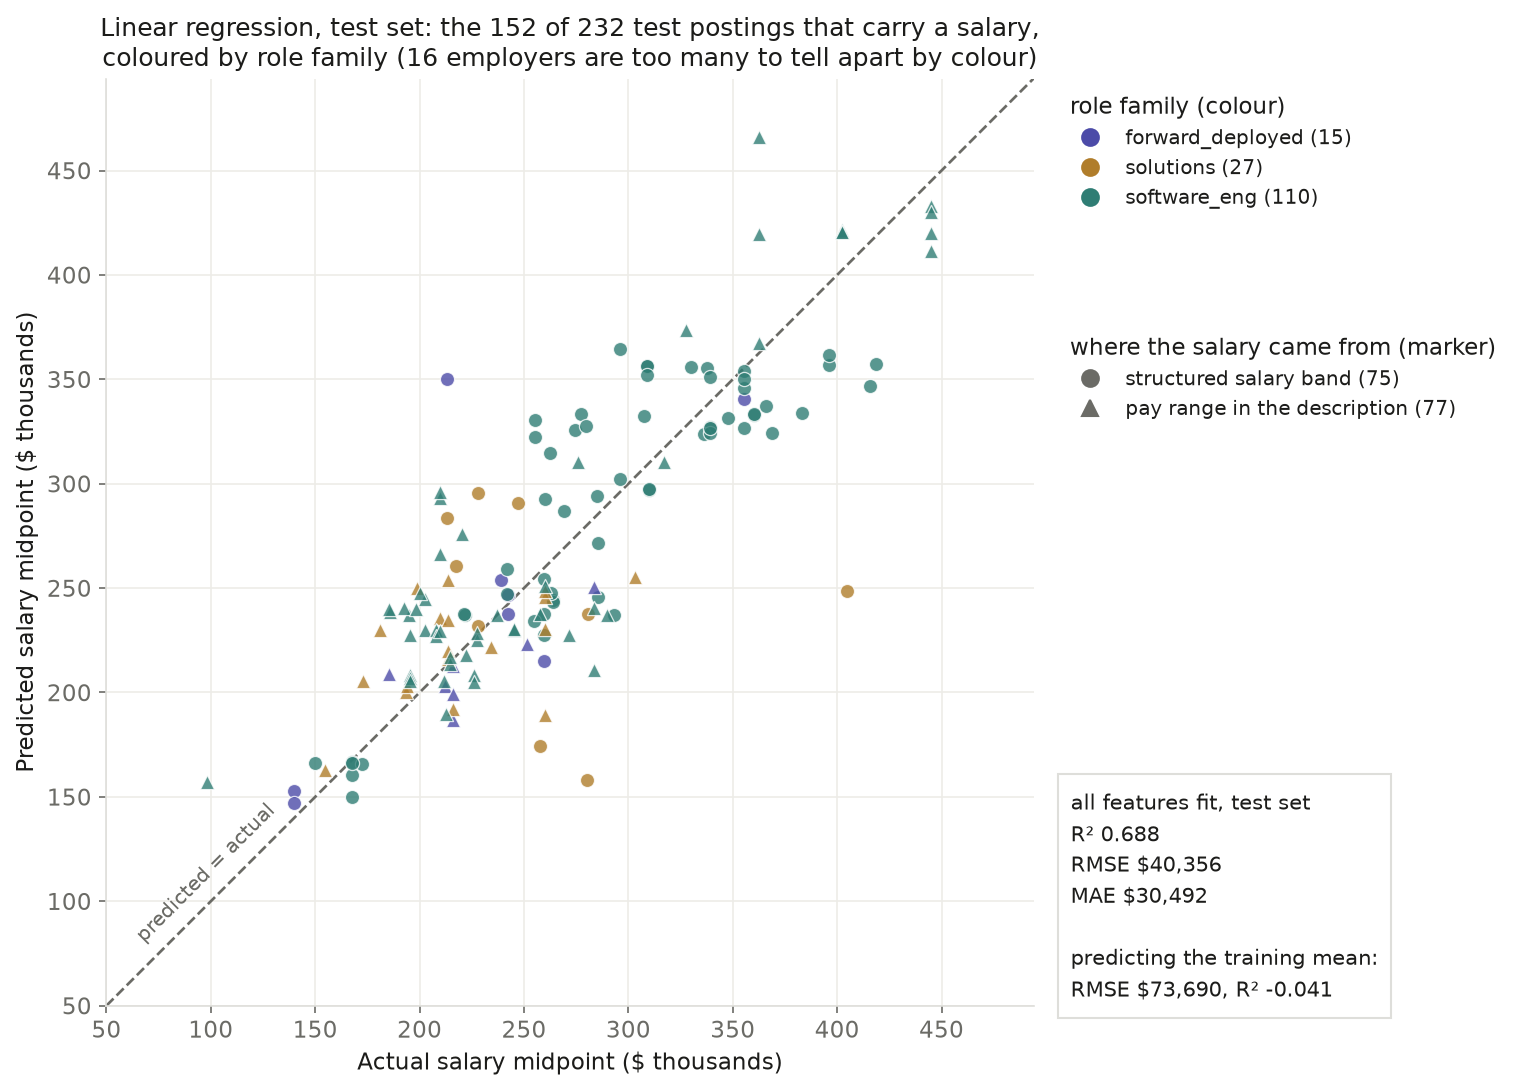

In [6]:
fig = rm.plot_pred_vs_actual(lin["preds"], lin["table"])
save(fig, "reg_pred_vs_actual")

## Insight
With all features, the model explains about 69% of the differences in salary (R² 0.688), and its typical miss is about $30,000. Company alone explains 55%; without company and department, only 14%.

### Coefficients

In [7]:
show(rm.coefficient_lines(lin["models"], tr))


ALL-FEATURES COEFFICIENTS, dollars of salary midpoint per unit; categories are differences from the reference level above, desc_len is dollars per character (x1,000 = -1,611 per 1,000 characters).
intercept 337,666; 136 encoded columns; rank of the training design with intercept 134 of 137
  the design is rank-deficient: some departments belong to a single company, so their department and company columns are not separately identified, and least squares splits the effect between them. The role family, work mode, location and desc_len coefficients, and the company-only fit's coefficients, do not have this problem.
                                                    column  dollars
                                   department_Early Career -139,984
                                    company_clean_Palantir -132,411
                          department_University Recruiting -125,957
                      department_AI Research & Engineering  125,644
                                     de

## Insight
Compared with a software engineer at the same company, department and location, a solutions posting pays about $40,000 less and a forward deployed posting about $21,000 less. With company as the only feature, Palantir postings average about $178,000 less than OpenAI's, and Anthropic's about $62,000 more.

### Multi-zone rows

In [8]:
show(rm.multizone_lines(tr, te, lin["preds"]))
show(["", "MULTI-ZONE RESIDUAL CHECK", *rm.multizone_residual_lines(df)])

where the multi-zone sensitivity comes from: training rows that are multi-zone, by company (multi-zone / all): Amplitude 2/2, Databricks 7/137, Scale AI 11/34, Webflow 2/2
  change in test squared error when they are left out, by company (billions of dollars squared; + is worse): Amplitude +16.7, Scale AI +12.3, Webflow +9.0, Harvey +2.6, Discord +0.6, Ramp -0.5, Cohere -0.5, Databricks -2.0
  departments with at least 3 training rows, half or more of them multi-zone: Scale AI 'Public Sector Engineering' 9/10



MULTI-ZONE RESIDUAL CHECK
residual = actual minus predicted midpoint, all-features fit; an overstated multi-zone salary shows up as a positive residual (the fit predicts less than the recorded top-zone value)
  test rows: multi-zone n 3, mean -10,903, median -9,195 | single-zone n 149, mean -3,572, median +763 | difference in means -7,330; Welch t-test p = 0.410, Mann-Whitney p = 0.562, permutation p = 0.735
  training rows, out of fold (10 x 5-fold): multi-zone n 22, mean -15,538, median -14,443 | single-zone n 563, mean -1,054, median -303 | difference in means -14,484; Welch t-test p = 0.206, Mann-Whitney p = 0.114, permutation p = 0.129
  training rows, out of fold, text salaries at Amplitude, Databricks, Scale AI, Webflow only: multi-zone n 22, mean -15,538, median -14,443 | single-zone n 153, mean -37, median -842 | difference in means -15,502; Welch t-test p = 0.183, Mann-Whitney p = 0.081, permutation p = 0.064
    Amplitude text salaries only: too few rows (multi-zone 2, sing

## Insight
Postings with several pay zones are not overstated: the model predicts them slightly higher than their recorded pay, and the difference is within noise. The lower R² when they are dropped comes about two-thirds from Amplitude and Webflow dropping out of training altogether, so their test postings are priced like OpenAI's, and about a third from Scale AI losing 11 of its 34 training rows.

### Duplicate bands

In [9]:
show(rm.duplicate_lines(tr, te, refs))

rows identical on the five categorical features and the band:
  training 585 -> 407 after collapsing; test 152 -> 138; test rows with an identical twin in training: 72
  all-features CV R2 on training rows (5x20 folds): 0.720 -> 0.605
  test R2, trained on collapsed rows: full test 0.666; collapsed test 0.649
rows identical on those and desc_len:
  training 585 -> 581 after collapsing; test 152 -> 152; test rows with an identical twin in training: 2
  all-features CV R2 on training rows (5x20 folds): 0.720 -> 0.719
  test R2, trained on collapsed rows: full test 0.691; collapsed test 0.691
(the 0.746 -> 0.70 in the Module 4 data check was ridge regression on structured salaries only, so the levels differ; the drop is the comparable part)


## Insight
Employers often post the same pay band many times: 72 of the 152 test rows have an exact twin in training. Counting each band only once lowers cross-validated R² from 0.72 to 0.61, so part of the fit comes from these repeats.

## 2. Logistic regression: forward_deployed against the rest

In [10]:
texts, y_fd, train, test = rm.binary_data(subset)
show(rm.baseline_lines(y_fd.iloc[train], y_fd.iloc[test]))

label: forward_deployed = 1, solutions and software_eng = 0; masked text, Module 3 split
  training 130 positive / 797 negative; test 33 / 199
  majority baseline on test (always 0): accuracy 0.8578 (199/232), balanced accuracy 0.500, recall 0, F1 0, AUC 0.500, AP = prevalence 0.142
  one test positive = 3.0 points of recall; one test posting = 0.43 points of accuracy


In [11]:
# C (logistic) and alpha (Naive Bayes) by stratified 5-fold CV on the training rows, scored on F1
logit = rm.fit_binary(texts, y_fd, train, test)
show(rm.tuning_lines(logit))


C by stratified 5-fold CV on training rows, scored on f1 (class_weight='balanced'):
        cv_mean  cv_sd
C                     
0.01     0.8565 0.0448
0.03     0.8584 0.0476
0.10     0.8728 0.0452
0.30     0.8705 0.0492
1.00     0.9031 0.0313
3.00     0.9070 0.0314
10.00    0.9103 0.0278
30.00    0.9096 0.0279
100.00   0.9096 0.0279
selected C = 10

MultinomialNB alpha by the same CV (f1):
       cv_mean  cv_sd
alpha                
0.01    0.8176 0.0533
0.05    0.8165 0.0451
0.10    0.8096 0.0476
0.50    0.7128 0.0601
1.00    0.5355 0.0728
selected alpha = 0.01

BernoulliNB alpha by the same CV (f1):
       cv_mean  cv_sd
alpha                
0.01    0.8228 0.0526
0.05    0.8288 0.0425
0.10    0.8306 0.0437
0.50    0.8190 0.0367
1.00    0.8044 0.0389
selected alpha = 0.1


### Test set

In [12]:
show(rm.test_lines(logit["results"], y_fd.iloc[test]))


TEST SET (232 postings, 33 forward_deployed); threshold 0.5; majority-baseline accuracy 0.8578
'unbalanced (default)' is the same C without class weights, so the gap is the effect of balancing.
                               TP FN FP  TN accuracy balanced_acc precision recall     F1    AUC     AP
logistic, balanced             29  4  4 195   0.9655       0.9293    0.8788 0.8788 0.8788 0.9878 0.9383
logistic, unbalanced (default) 26  7  1 198   0.9655       0.8914    0.9630 0.7879 0.8667 0.9883 0.9435
MultinomialNB, alpha 0.01      21 12  1 198   0.9440       0.8157    0.9545 0.6364 0.7636 0.9796 0.9017
BernoulliNB, alpha 0.1         23 10  1 198   0.9526       0.8460    0.9583 0.6970 0.8070 0.9670 0.8732
  logistic, balanced: confusion [[TN 195, FP 4], [FN 4, TP 29]]; recall 29/33, 95% interval 0.727-0.952
  logistic, unbalanced (default): confusion [[TN 198, FP 1], [FN 7, TP 26]]; recall 26/33, 95% interval 0.622-0.893
  MultinomialNB, alpha 0.01: confusion [[TN 198, FP 1], [FN 12, T

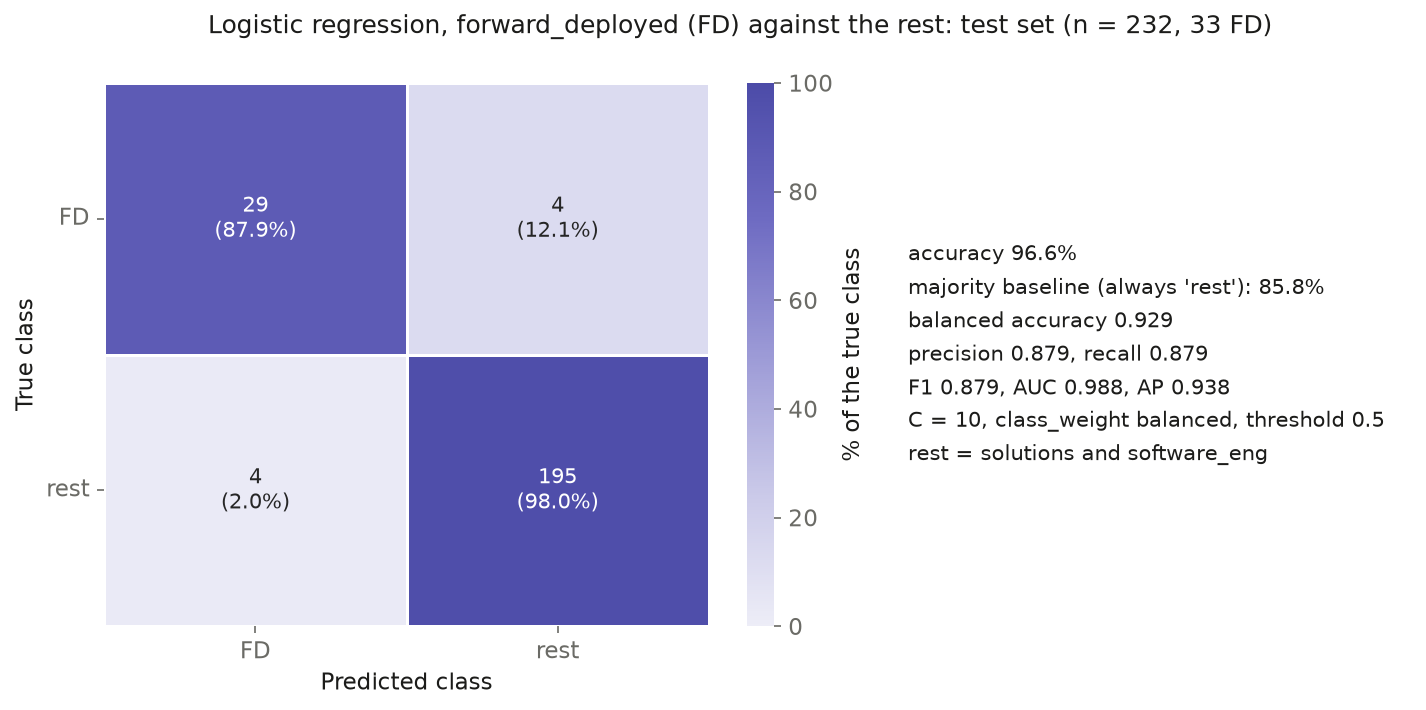

In [13]:
fig = rm.plot_confusion_logistic(logit["results"]["logistic, balanced"], y_fd.iloc[test], logit["best_c"])
save(fig, "reg_confusion_logistic")

## Insight
The logistic model finds 29 of the 33 forward deployed postings and wrongly flags only 4 of the other 199. It is right 96.6% of the time, against 85.8% for always guessing "not forward deployed". Without class balancing it finds only 26.

### Against Naive Bayes on the same label

In [14]:
show(rm.separation_lines(logit["results"], y_fd.iloc[test]))


HOW MANY TEST POSTINGS SEPARATE THE MODELS (exact McNemar test on the postings they disagree on)
  logistic, balanced vs logistic, unbalanced (default): postings classified differently 6; right only by the first 3, only by the second 3 (p = 1.000); forward_deployed found 29 vs 26 (+3 postings, +9.1 recall points; on the 33 positives alone 3 vs 0 found by only one, p = 0.250); false positives 4 vs 1
  logistic, balanced vs MultinomialNB, alpha 0.01: postings classified differently 11; right only by the first 8, only by the second 3 (p = 0.227); forward_deployed found 29 vs 21 (+8 postings, +24.2 recall points; on the 33 positives alone 8 vs 0 found by only one, p = 0.008); false positives 4 vs 1
  logistic, balanced vs BernoulliNB, alpha 0.1: postings classified differently 9; right only by the first 6, only by the second 3 (p = 0.508); forward_deployed found 29 vs 23 (+6 postings, +18.2 recall points; on the 33 positives alone 6 vs 0 found by only one, p = 0.031); false positives 4 vs

## Insight
On the same yes-or-no question, logistic regression finds more forward deployed postings than Naive Bayes: 29, against 21 for Multinomial and 23 for Bernoulli. It makes 3 more false alarms, so overall accuracy is not clearly better.

### What the logistic model weighs

In [15]:
show(rm.word_lines(logit["balanced"], texts, y_fd, train))


BALANCED LOGISTIC COEFFICIENTS as odds ratios. A TF-IDF weight of 1.0 is the whole posting; the typical weight is the median weight among training postings that use the word, and OR_at_typical is the odds ratio for a posting that uses the word at that weight. Intercept -3.525.
20 highest (toward forward_deployed):
       word   coef OR_per_1.0 OR_per_0.1 typical_weight OR_at_typical  in_forward_deployed_of_130  in_rest_of_797
   customer +4.879        131      1.629          0.074         1.432                         108             406
 production +3.801       44.7      1.462          0.041         1.167                          89             462
   delivery +3.757       42.8      1.456          0.074         1.321                          66             141
engagements +3.343       28.3      1.397          0.055         1.202                          36              70
     travel +3.220         25      1.380          0.039         1.135                          93             112

## Insight
Words like customer, delivery, engagements and travel push a posting toward forward deployed; words like infrastructure, platform and performance push it away. A posting that uses "customer" at its usual rate has about 1.4 times the odds of being forward deployed.

## 3. AdaBoost: role family

### Grid search (skipped by default)

In [16]:
# GRID SEARCH: about 4.5 minutes for both feature sets. Skipped by default; the
# cell below loads the curves it last wrote to results/adaboost_cv_curve.csv. Set RUN_GRID_SEARCH = True
# only when the data or the features change; it rewrites that file.
RUN_GRID_SEARCH = False
y = subset["role_family"]
if RUN_GRID_SEARCH:
    ra.save_curves(ra.grid_search(subset, y, train))
    print("grid search run; curves written to", ra.CURVE_PATH.relative_to(nb.tc.ROOT))
else:
    print("grid search skipped; using the saved curves in", ra.CURVE_PATH.relative_to(nb.tc.ROOT))

grid search skipped; using the saved curves in results/adaboost_cv_curve.csv


In [17]:
curves = ra.load_curves()
selected = {ra.TABULAR: ra.select(curves[ra.TABULAR], ra.TABULAR_ROUNDS),
            ra.TEXT: ra.select(curves[ra.TEXT], ra.TEXT_ROUNDS)}
for label, (rate, rounds) in selected.items():
    print(f"SELECTED ({label}): learning_rate {rate:g}, n_estimators {rounds}")
show(["", *ra.setup_lines(), "", *ra.surface_lines(curves[ra.TABULAR], ra.TABULAR_ROUNDS)])

SELECTED (tabular (tree 1)): learning_rate 1, n_estimators 750
SELECTED (masked TF-IDF (tree 4)): learning_rate 0.5, n_estimators 750

features: tree 1's nine columns department, company_clean, location_clean, workplaceType, salary_annual_min, salary_annual_max, desc_len, location_count, is_multi_location; encoded by role_dt.tabular_encoder inside the pipeline, so every CV fold refits it
base estimator: decision stump; grid learning_rate [0.05, 0.1, 0.25, 0.5, 1.0, 1.5] x n_estimators [10, 25, 50, 100, 200, 300, 500, 750, 1000, 1500], stratified 5-fold CV on the 927 training rows, accuracy

mean CV accuracy (rows n_estimators, columns learning_rate):
learning_rate   0.05   0.10   0.25   0.50   1.00   1.50
n_estimators                                           
10            0.6376 0.6797 0.6839 0.7227 0.7508 0.8091
25            0.6602 0.7033 0.7324 0.7616 0.7961 0.8619
50            0.6839 0.7120 0.7551 0.8036 0.8457 0.8727
100           0.7033 0.7497 0.7821 0.8285 0.8587 0.8802
200  

### Validation accuracy as rounds are added

tree 1 CV accuracy on the same folds: 0.8910


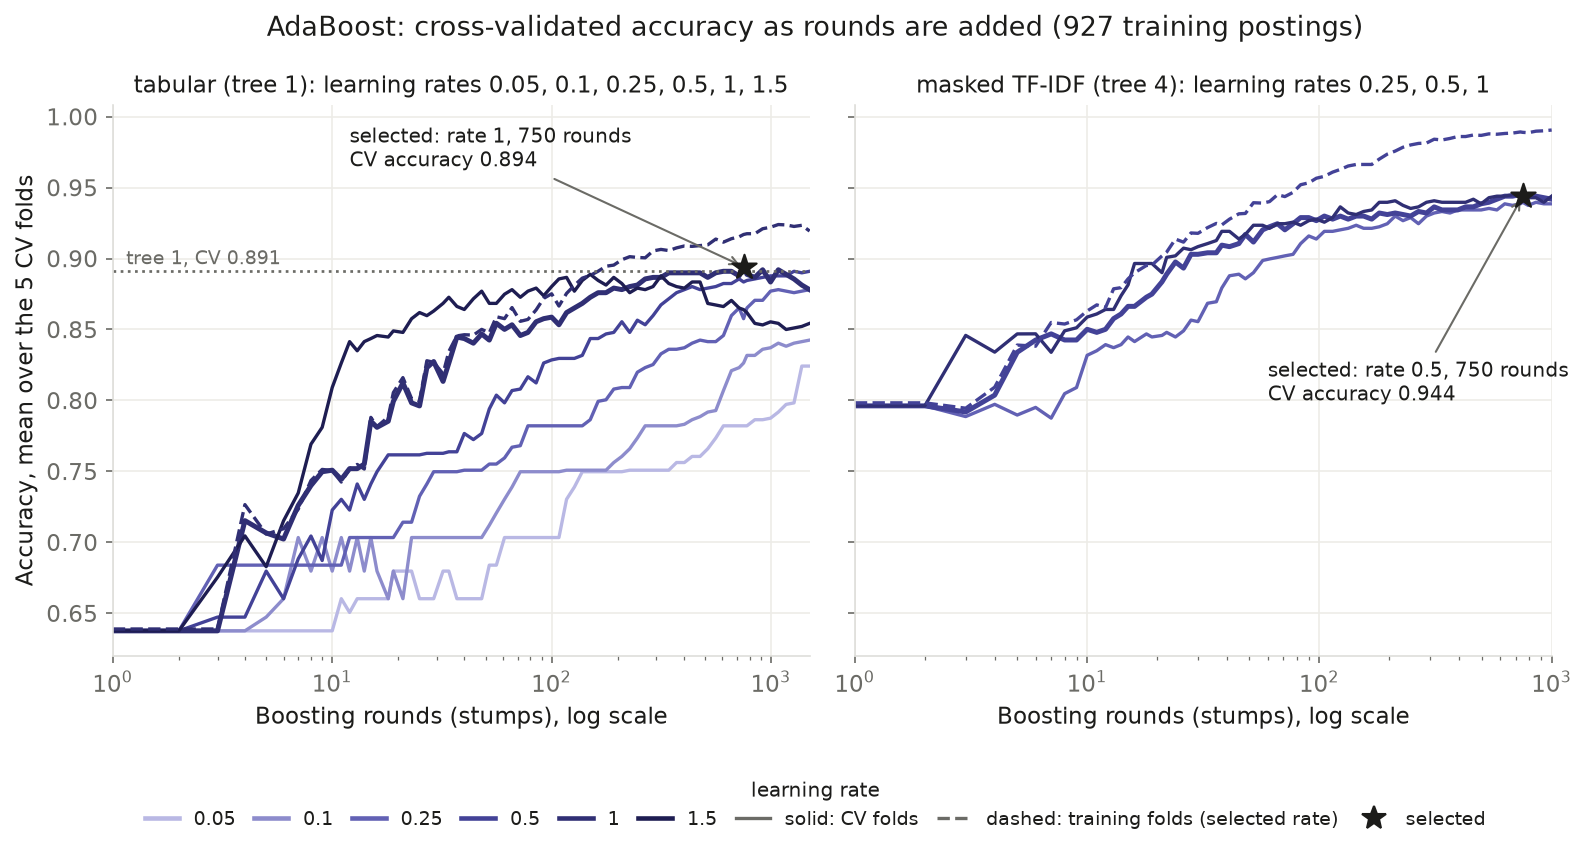

In [18]:
# tree 1's CV accuracy on the same five folds, drawn as a reference line
X_tab = dt.tabular_frame(subset)
folds = StratifiedKFold(nb.CV_FOLDS, shuffle=True, random_state=nb.SPLIT_SEED)
tree1_cv = cross_val_score(dt.make_model(*ra.TREE1[:3]), X_tab.iloc[train], y.iloc[train], cv=folds,
                           scoring="accuracy").mean()
print(f"tree 1 CV accuracy on the same folds: {tree1_cv:.4f}")
fig = ra.plot_cv_curve(curves, selected, {ra.TABULAR: ("tree 1, CV", tree1_cv)})
save(fig, "ab_cv_curve")

## Insight
Small learning rates are still behind after 1,500 rounds, while a rate of 1.5 peaks early and then gets worse. The chosen setting, rate 1 with 750 rounds, scores 0.894 in cross-validation, about the same as tree 1 (0.891), and its training accuracy stays near 92%.

### Selected model on the test set

In [19]:
# only the selected pair is refitted, on all 927 training rows
tab = ra.fit_tabular(subset, y, train, test, curves[ra.TABULAR])
show([ra.selection_line(tab), "", "TEST SET (232 postings)", *ra.result_lines("AdaBoost (tabular)", tab["ada"])])

SELECTED: learning_rate 1, n_estimators 750 (CV accuracy 0.8942); final model fitted on all 927 training rows with 750 stumps

TEST SET (232 postings)
AdaBoost (tabular): test accuracy 0.8664, macro F1 0.8234, train accuracy 0.9213, gap 0.0549
confusion matrix (rows true, columns predicted):
predicted  FD  Sol  SWE
true                   
FD         23    3    7
Sol         1   36   18
SWE         0    2  142
    precision recall     F1  support
FD     0.9583 0.6970 0.8070       33
Sol    0.8780 0.6545 0.7500       55
SWE    0.8503 0.9861 0.9132      144


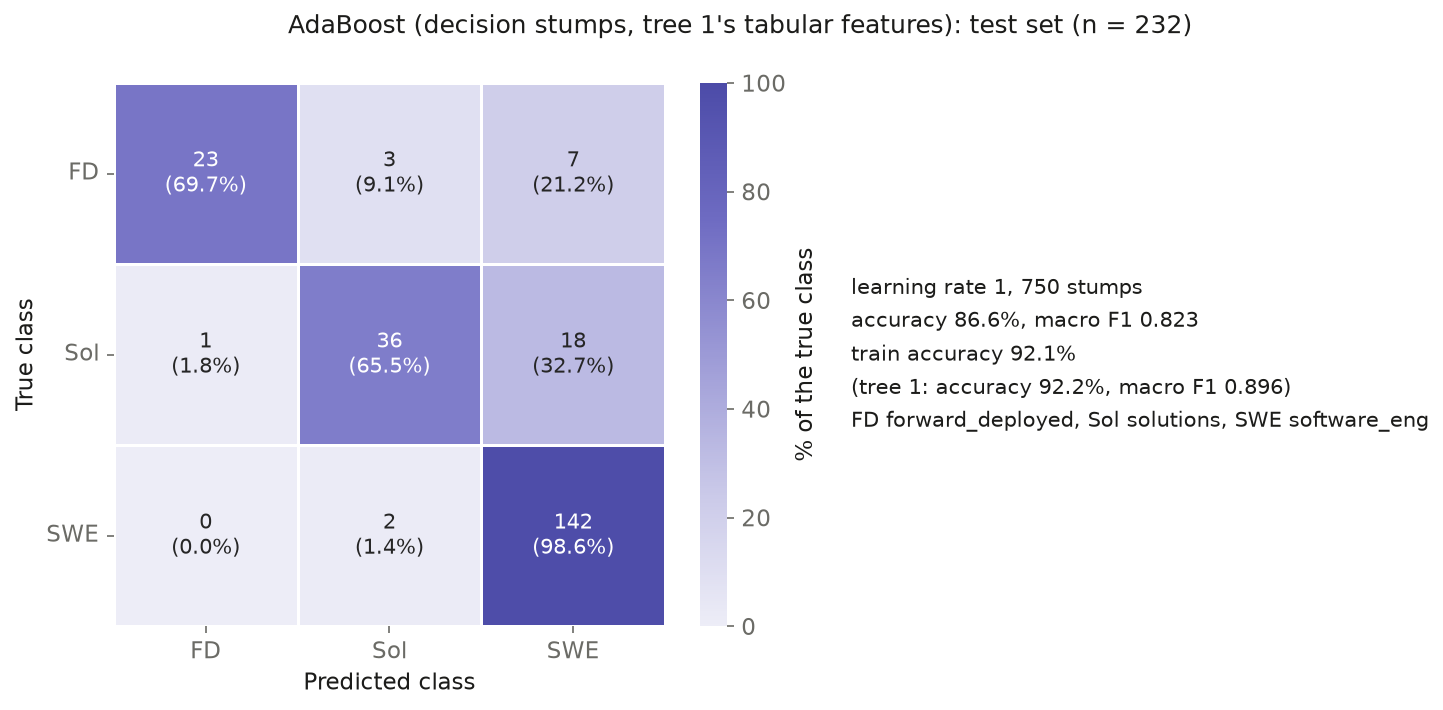

In [20]:
ada = tab["ada"]
notes = [f"learning rate {tab['rate']:g}, {tab['rounds']} stumps",
         f"accuracy {ada['accuracy']:.1%}, macro F1 {ada['macro_f1']:.3f}",
         f"train accuracy {ada['train_accuracy']:.1%}",
         f"(tree 1: accuracy {tab['tree1']['accuracy']:.1%}, macro F1 {tab['tree1']['macro_f1']:.3f})",
         "FD forward_deployed, Sol solutions, SWE software_eng"]
fig = ra.plot_confusion(ada, f"AdaBoost (decision stumps, tree 1's tabular features): test set (n = {len(test)})", notes)
save(fig, "ab_confusion")

## Insight
AdaBoost gets 86.6% of test postings right. It almost never misses a software engineering posting (142 of 144), but it calls 18 of the 55 solutions postings software engineering.

### What AdaBoost relies on

In [21]:
show(ra.importance_lines(tab["model"]))

feature importance (share of the weighted impurity decrease across all stumps); 61 of 222 encoded columns are used by at least one stump
by input column: department 0.778, company_clean 0.092, location_clean 0.076, salary_annual_min 0.024, desc_len 0.017, salary_annual_max 0.012
top 15 encoded columns:
department = Forward Deployed Engineering       0.0820
department = Professional Services Operations   0.0641
department = Field Engineering - BIF            0.0419
location_clean = Brazil                         0.0409
department = Delta                              0.0394
department = Engineering & Infra                0.0386
department = Engineering                        0.0365
department =  Field Engineering - Indirect      0.0350
department = Echo                               0.0293
department = Engineering - Pipeline             0.0286
department = Field Engineering - Other          0.0281
department = Dev                                0.0244
department = Modeling               

## Insight
Department does most of the work: about 78% of what AdaBoost relies on, far ahead of company (9%) and location (8%). Like tree 1, it mostly reads the employers' team names.

### AdaBoost against tree 1

In [22]:
show([*ra.result_lines("tree 1 (refitted; matches the published 0.9224)", tab["tree1"]), "",
      *ra.comparison_lines({"AdaBoost": tab["ada"], "tree 1": tab["tree1"]}, y.iloc[test]), "",
      *ra.fold_lines(ra.tree_fold_models(tab), tab["X"], y, train)])

tree 1 (refitted; matches the published 0.9224): test accuracy 0.9224, macro F1 0.8955, train accuracy 1.0000, gap 0.0776
confusion matrix (rows true, columns predicted):
predicted  FD  Sol  SWE
true                   
FD         26    2    5
Sol         1   49    5
SWE         2    3  139
    precision recall     F1  support
FD     0.8966 0.7879 0.8387       33
Sol    0.9074 0.8909 0.8991       55
SWE    0.9329 0.9653 0.9488      144

         test accuracy macro F1 recall FD recall Sol recall SWE train accuracy    gap correct (of 232)
AdaBoost        0.8664   0.8234    0.6970     0.6545     0.9861         0.9213 0.0549              201
tree 1          0.9224   0.8955    0.7879     0.8909     0.9653         1.0000 0.0776              214
AdaBoost vs tree 1: 25 test postings separate them; right only by AdaBoost 6, only by tree 1 19; net -13 postings = -5.60 accuracy points (one posting = 0.43); exact McNemar p = 0.015
  by role family (right only by AdaBoost vs only by tree 1): FD 0 v

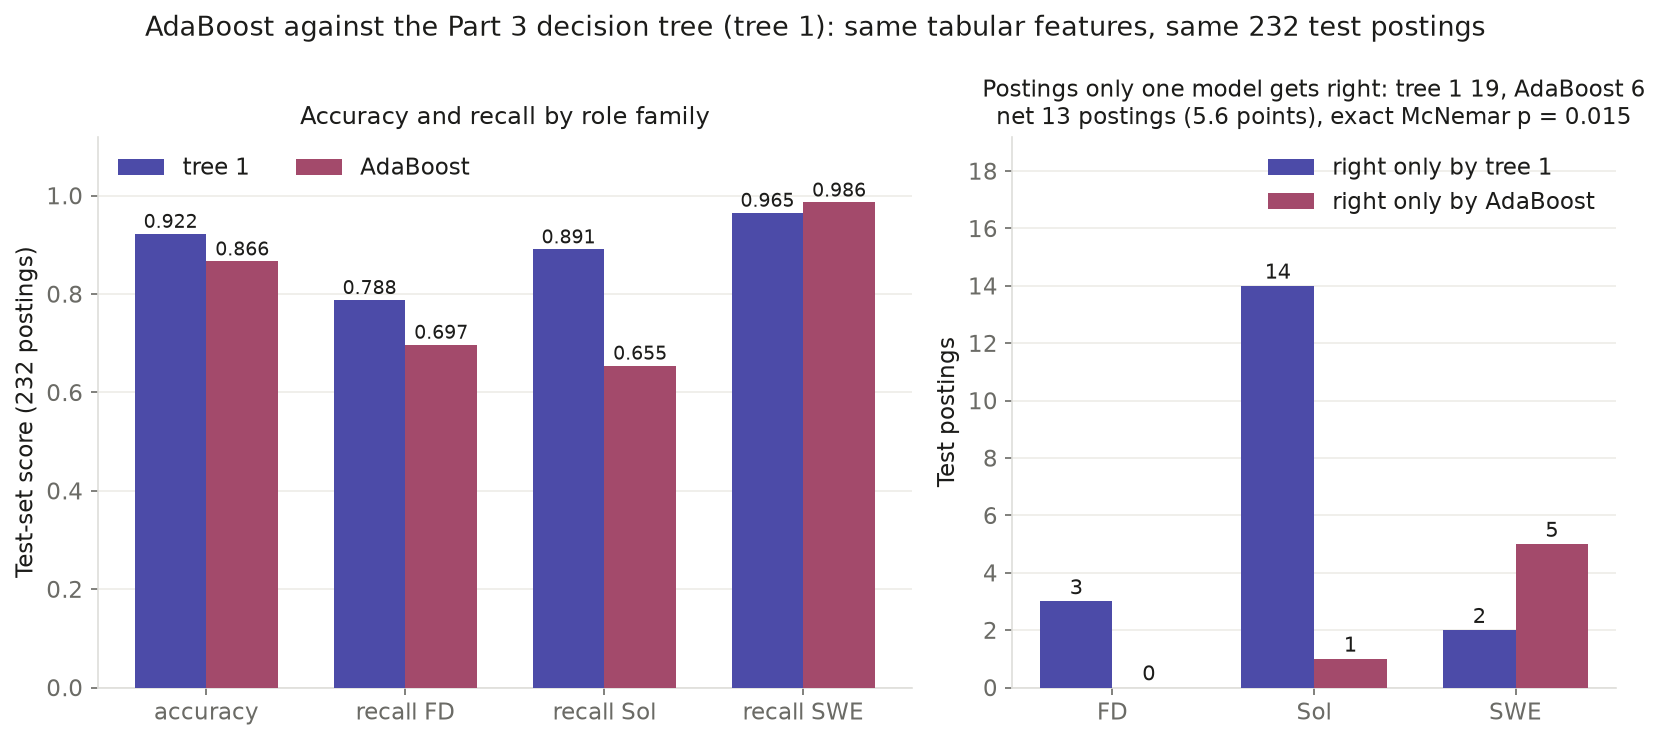

In [23]:
fig = ra.plot_vs_tree(tab["ada"], tab["tree1"], y.iloc[test])
save(fig, "ab_vs_tree")

## Insight
Tree 1 beats AdaBoost on the test set by 13 postings (5.6 points), and 14 of tree 1's 19 extra correct answers are solutions postings. In cross-validation the two were almost equal, so part of this gap comes from this particular test set.

### AdaBoost on the masked text

In [24]:
txt = ra.fit_text(subset, y, train, test, curves[ra.TEXT])
show([ra.text_setup_line(), "", *ra.surface_lines(curves[ra.TEXT], ra.TEXT_ROUNDS), "",
      f"SELECTED: learning_rate {txt['rate']:g}, n_estimators {txt['rounds']}", "",
      *ra.result_lines("AdaBoost (masked text)", txt["ada"]), "",
      *ra.comparison_lines(txt["results"], y.iloc[test])])

smaller grid to keep it cheap: learning_rate [0.25, 0.5, 1.0] x n_estimators [25, 50, 100, 200, 300, 500, 750, 1000]; the vectoriser is refitted inside every fold

mean CV accuracy (rows n_estimators, columns learning_rate):
learning_rate   0.25   0.50   1.00
n_estimators                      
25            0.8458 0.8954 0.9041
50            0.8878 0.9138 0.9202
100           0.9170 0.9256 0.9267
200           0.9245 0.9299 0.9385
300           0.9332 0.9353 0.9375
500           0.9332 0.9375 0.9396
750           0.9396 0.9440 0.9439
1000          0.9385 0.9418 0.9439
CV accuracy, sd across the 5 folds (rows n_estimators, columns learning_rate):
learning_rate   0.25   0.50   1.00
n_estimators                      
25            0.0271 0.0311 0.0286
50            0.0243 0.0387 0.0307
100           0.0322 0.0336 0.0303
200           0.0290 0.0323 0.0269
300           0.0246 0.0270 0.0260
500           0.0292 0.0299 0.0260
750           0.0318 0.0232 0.0229
1000          0.0246 0.0239 0.0

## Insight
On the job description text, AdaBoost gets 92.2% right, 8 postings more than tree 4, but that gap is within noise. It is level with the two Naive Bayes models, within 2 or 3 postings.

### Runtime

In [25]:
print(f"notebook ran in {time.perf_counter() - START:.1f} s "
      f"(AdaBoost grid search {'run' if RUN_GRID_SEARCH else 'skipped'})")

notebook ran in 34.7 s (AdaBoost grid search skipped)
